# Graph Modelling – Product co-purchase network
**Input:** cleaned sales from Component C. All logic is in `graph.py`; this notebook calls those functions step by step, so the two cannot disagree.

## 1. Property graph model
A *property graph* has labelled nodes, typed relationships, and properties on both. The source data fits this model:

| Element | Label / type | Properties | Source |
|---|---|---|---|
| Node | `Product` | stock_code (key), name, invoice_count, total_quantity, total_revenue | StockCode, Description |
| Node | `Invoice` | invoice_no (key), invoice_date | InvoiceNo, InvoiceDate |
| Node | `Customer` | customer_id (key) | CustomerID (may be absent) |
| Node | `Country` | name, iso2 | Country, CountryISO2 |
| Relationship | `(Customer)-[:PLACED]->(Invoice)` | – | invoice header |
| Relationship | `(Invoice)-[:CONTAINS]->(Product)` | quantity, unit_price | each cleaned row |
| Relationship | `(Invoice)-[:RECORDED_FOR_COUNTRY]->(Country)` | – | invoice header |
| **Analysed projection** | `(Product)-[:CO_PURCHASED_WITH]-(Product)` | weight, lift, jaccard | derived |

The analysis uses the **Product–Product projection**: two products are linked when they share an invoice. It is undirected because sharing an invoice has no direction. Customer and Country nodes are not used in the NetworkX analysis.

**Why Country is linked to Invoice, not Customer.** In the cleaned sales, 8 of 4,333 customers appear under two countries, while every invoice has exactly one country. A customer-level link would force a single, possibly wrong, country on those customers. UCI describes the field as the customer's country of residence, but the recorded value belongs to the invoice.

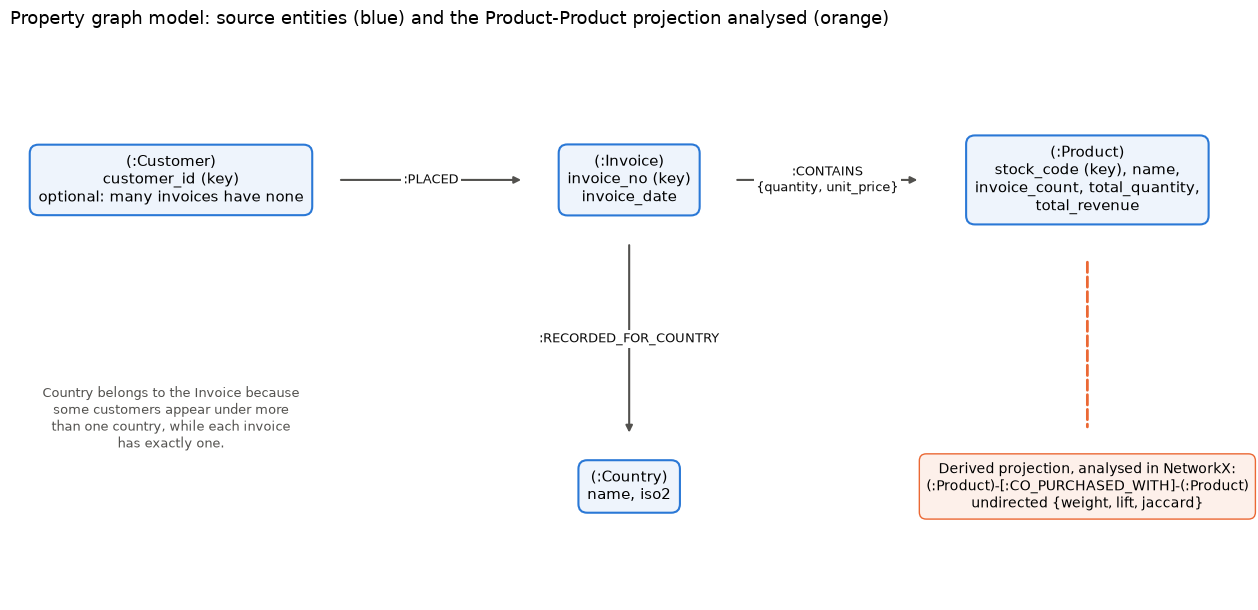

In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
import graph as gm

gm.OUTPUT_DIR.mkdir(exist_ok=True)
gm.draw_property_model(gm.OUTPUT_DIR / "property_graph_model.png")
plt.show()

## 2. Build the graph
1. Load cleaned sales, leaving out sales later cancelled in full (a reversed purchase is not a co-purchase).
2. Take the 100 products on the most invoices as **candidates**.
3. Count shared invoices for each of the possible pairs.
4. Keep the 300 strongest pairs. A candidate with no kept edge does not appear, so the graph has **fewer than 100 nodes**.

Edge properties: `weight` = shared invoices; `jaccard` = shared invoices divided by invoices with either product; `lift` = how many times more often the pair occurs than if the products were independent (1 = no association).

In [2]:
sales = gm.load_sales()
G, construction = gm.build_graph(sales)
print(json.dumps(construction, indent=2))

# Independent check of one edge directly from the data, without using the graph code
a, b, w = max(G.edges(data="weight"), key=lambda e: e[2])
direct = len(set(sales.loc[sales.StockCode == a, "InvoiceNo"]) & set(sales.loc[sales.StockCode == b, "InvoiceNo"]))
print(f"Strongest edge {a}-{b}: graph weight {w}, direct count {direct}")
assert w == direct

{
  "invoices_in_cleaned_sales": 19647,
  "candidate_products": 100,
  "distinct_candidate_pairs": 4950,
  "edges_kept": 300,
  "weakest_kept_weight": 258,
  "pairs_tied_at_cutoff": 2,
  "ties_cut_off": 1
}
Strongest edge 22386-85099B: graph weight 817, direct count 817


## 3. Measures
Degree centrality = the share of other products directly linked. Betweenness = how often a product lies on shortest paths between others. It is calculated twice: counting hops, and treating strong links as short (distance = 1/weight). Comparing the two shows whether a position depends on how distance is defined.

In [3]:
metrics, summary = gm.add_metrics(G)
gm.export(G, metrics, summary, construction)
print(json.dumps(summary, indent=2))
columns = ["product", "invoice_count", "degree", "degree_centrality", "weighted_degree", "betweenness", "betweenness_weighted", "community"]
pd.set_option("display.width", 200)
print("\nTop 10 by degree"); display(metrics.sort_values("degree", ascending=False).head(10)[columns])
print("Top 10 by betweenness"); display(metrics.sort_values("betweenness", ascending=False).head(10)[columns])

{
  "nodes": 82,
  "edges": 300,
  "density": 0.0903,
  "connected_components": 7,
  "component_sizes": [
    66,
    4,
    3,
    3,
    2,
    2,
    2
  ],
  "largest_component_nodes": 66,
  "average_clustering": 0.589,
  "average_clustering_weighted": 0.2711,
  "communities_greedy_whole_graph": 10,
  "community_sizes_greedy_whole_graph": [
    30,
    18,
    15,
    4,
    3,
    3,
    3,
    2,
    2,
    2
  ],
  "modularity_greedy_whole_graph": 0.486,
  "communities_greedy_largest_component": 4,
  "modularity_greedy_largest_component": 0.4523,
  "communities_louvain_largest_component": 4,
  "modularity_louvain_largest_component": 0.469,
  "spearman_popularity_vs_degree": 0.541
}

Top 10 by degree


,product,invoice_count,degree,degree_centrality,weighted_degree,betweenness,betweenness_weighted,community
StockCode,,,,,,,,
85099B,JUMBO BAG RED RETROSPOT,2078,44,0.5432,17571,0.2376,0.3222,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,2253,28,0.3457,8977,0.1865,0.1793,0
20725,LUNCH BAG RED RETROSPOT,1557,26,0.3210,10459,0.0456,0.0938,2
21931,JUMBO STORAGE BAG SUKI,1179,22,0.2716,8012,0.0277,0.0000,1
20727,LUNCH BAG BLACK SKULL.,1267,21,0.2593,7833,0.0218,0.0006,2
22383,LUNCH BAG SUKI DESIGN,1281,20,0.2469,7728,0.0164,0.0012,2
20724,RED RETROSPOT CHARLOTTE BAG,1029,17,0.2099,6023,0.0054,0.0052,2
22423,REGENCY CAKESTAND 3 TIER,1946,17,0.2099,5571,0.0959,0.0985,0
22386,JUMBO BAG PINK POLKADOT,1209,17,0.2099,6516,0.0068,0.0000,1


Top 10 by betweenness


,product,invoice_count,degree,degree_centrality,weighted_degree,betweenness,betweenness_weighted,community
StockCode,,,,,,,,
85099B,JUMBO BAG RED RETROSPOT,2078,44,0.5432,17571,0.2376,0.3222,1
85123A,WHITE HANGING HEART T-LIGHT HOLDER,2253,28,0.3457,8977,0.1865,0.1793,0
22423,REGENCY CAKESTAND 3 TIER,1946,17,0.2099,5571,0.0959,0.0985,0
21212,PACK OF 72 RETROSPOT CAKE CASES,1315,16,0.1975,5031,0.0493,0.0410,0
20725,LUNCH BAG RED RETROSPOT,1557,26,0.3210,10459,0.0456,0.0938,2
22727,ALARM CLOCK BAKELIKE RED,1047,3,0.0370,1379,0.0389,0.0389,4
21931,JUMBO STORAGE BAG SUKI,1179,22,0.2716,8012,0.0277,0.0000,1
20727,LUNCH BAG BLACK SKULL.,1267,21,0.2593,7833,0.0218,0.0006,2
47566,PARTY BUNTING,1674,8,0.0988,2750,0.0208,0.0198,0


In [4]:
# Strongest pairs by lift
edges = gm.edge_table(G)
print("Strongest by weight"); display(edges.head(6)[["source_name", "target_name", "weight", "lift"]])
print("Strongest by lift"); display(edges.sort_values("lift", ascending=False).head(6)[["source_name", "target_name", "weight", "lift"]])
pd.set_option("display.max_colwidth", 130)
gm.community_table(metrics)

Strongest by weight


,source_name,target_name,weight,lift
0,JUMBO BAG PINK POLKADOT,JUMBO BAG RED RETROSPOT,817,6.389
60,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,760,14.028
17,JUMBO BAG RED RETROSPOT,JUMBO STORAGE BAG SUKI,718,5.758
18,JUMBO BAG RED RETROSPOT,JUMBO SHOPPER VINTAGE RED PAISLEY,676,5.467
99,LUNCH BAG RED RETROSPOT,LUNCH BAG SUKI DESIGN,653,6.432
100,LUNCH BAG RED RETROSPOT,LUNCH BAG BLACK SKULL.,637,6.344


Strongest by lift


,source_name,target_name,weight,lift
61,GREEN REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,626,16.070
194,GARDENERS KNEELING PAD CUP OF TEA,GARDENERS KNEELING PAD KEEP CALM,543,15.583
64,ROSES REGENCY TEACUP AND SAUCER,PINK REGENCY TEACUP AND SAUCER,590,14.430
60,GREEN REGENCY TEACUP AND SAUCER,ROSES REGENCY TEACUP AND SAUCER,760,14.028
227,CHARLOTTE BAG PINK POLKADOT,STRAWBERRY CHARLOTTE BAG,377,13.977
202,SPACEBOY LUNCH BOX,DOLLY GIRL LUNCH BOX,537,13.808


,community,size,top_products
0,0,30,WHITE HANGING HEART T-LIGHT HOLDER | REGENCY CAKESTAND 3 TIER | PACK OF 72 RETROSPOT CAKE CASES | SET OF 3 CAKE TINS PANTRY DE...
1,1,18,JUMBO BAG RED RETROSPOT | JUMBO STORAGE BAG SUKI | JUMBO BAG PINK POLKADOT | JUMBO SHOPPER VINTAGE RED PAISLEY | LUNCH BAG VIN...
2,2,15,LUNCH BAG RED RETROSPOT | LUNCH BAG BLACK SKULL. | LUNCH BAG SUKI DESIGN | RED RETROSPOT CHARLOTTE BAG | LUNCH BAG CARS BLUE
3,3,4,COOK WITH WINE METAL SIGN | GIN + TONIC DIET METAL SIGN | PLEASE ONE PERSON METAL SIGN | HAND OVER THE CHOCOLATE SIGN
4,4,3,ALARM CLOCK BAKELIKE RED | ALARM CLOCK BAKELIKE GREEN | ALARM CLOCK BAKELIKE PINK
5,5,3,CHOCOLATE HOT WATER BOTTLE | SCOTTIE DOG HOT WATER BOTTLE | HOT WATER BOTTLE KEEP CALM
6,6,3,SPACEBOY LUNCH BOX | DOLLY GIRL LUNCH BOX | LUNCH BOX I LOVE LONDON
7,7,2,PAPER CHAIN KIT 50'S CHRISTMAS | PAPER CHAIN KIT VINTAGE CHRISTMAS
8,8,2,GARDENERS KNEELING PAD CUP OF TEA | GARDENERS KNEELING PAD KEEP CALM
9,9,2,SET OF 3 HEART COOKIE CUTTERS | SET OF 3 BUTTERFLY COOKIE CUTTERS


## 4. Visualisation
The ten strongest bridges are numbered and named in the key, because printing all product names on the network would be unreadable. A GEXF file is exported for Gephi.

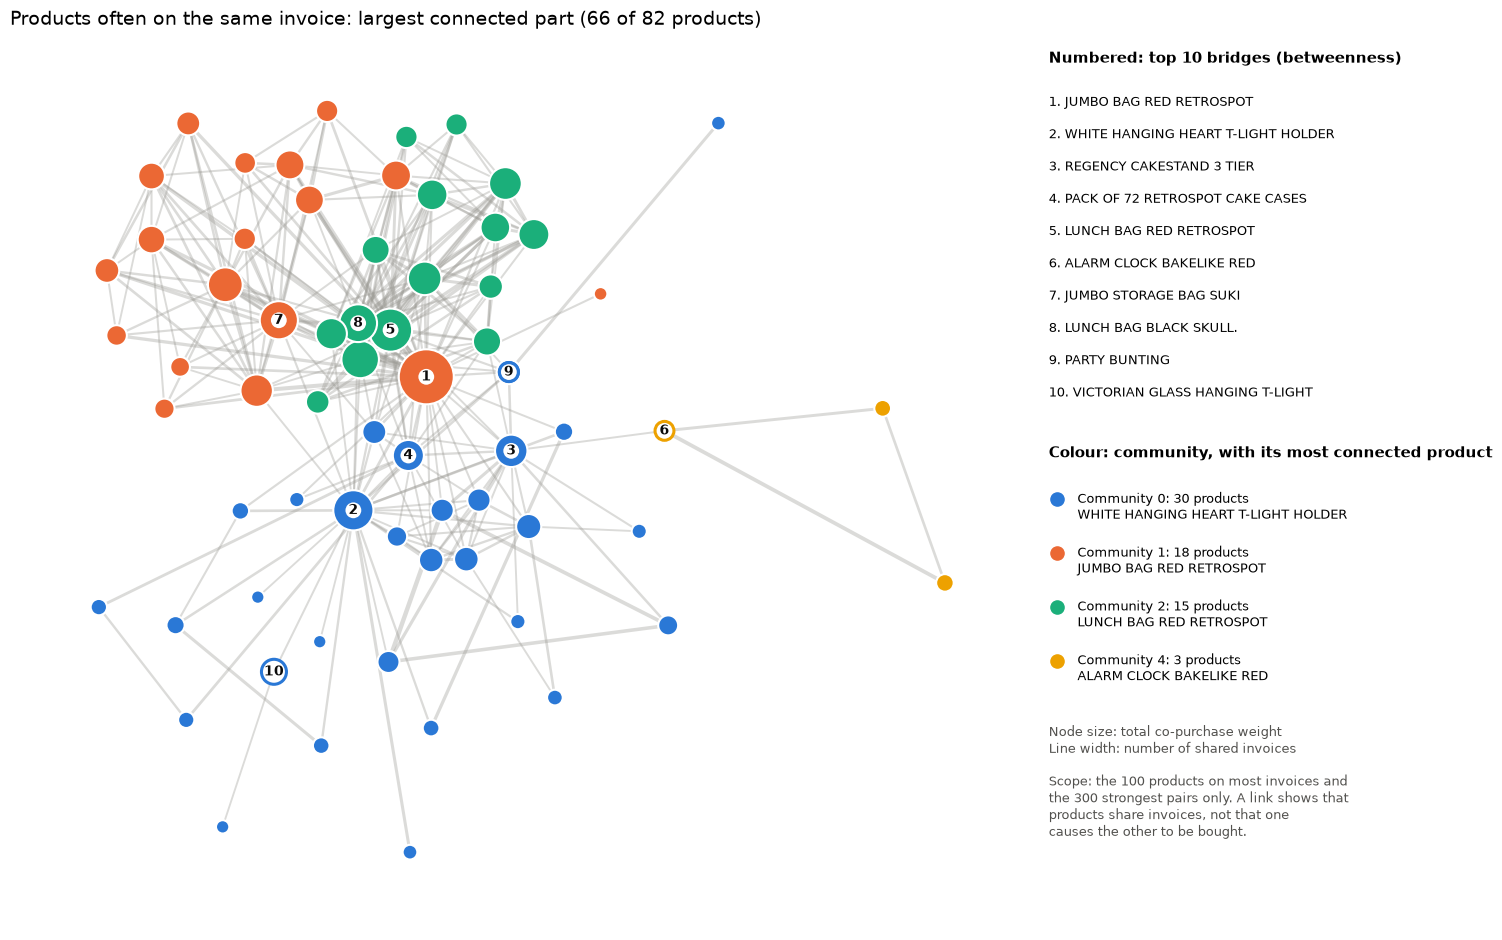

['community_summary.csv',
 'copurchase_network.gexf',
 'copurchase_network.png',
 'edge_list.csv',
 'graph_summary.json',
 'node_metrics.csv',
 'property_graph_model.png',
 'threshold_sensitivity.csv']

In [5]:
gm.draw_network(G, metrics, gm.OUTPUT_DIR / "copurchase_network.png")
plt.show()
sorted(p.name for p in gm.OUTPUT_DIR.iterdir())

## 5. Threshold sensitivity
The graph depends on two choices: 100 candidate products and 300 kept pairs. The same method is re-run with 50, 100 or 150 products and 150, 300 or 450 pairs. The baseline graph and its files are unchanged. This shows which conclusions hold under other choices.


In [6]:
sensitivity = gm.sensitivity_table(sales)
sensitivity.to_csv(gm.OUTPUT_DIR / "threshold_sensitivity.csv", index=False)
display(sensitivity)

base = sensitivity[sensitivity["is_baseline"]].iloc[0]
same_leader = int((sensitivity["highest_degree_product"] == base["highest_degree_product"]).sum())
print(f"{base['highest_degree_product']} has the highest degree in {same_leader} of {len(sensitivity)} settings.")
print(f"Top-10 degree products shared with the baseline: {sensitivity['top10_degree_shared_with_baseline'].min()} to {sensitivity['top10_degree_shared_with_baseline'].max()} of 10.")
print(f"Modularity of the largest component ranges from {sensitivity['modularity_largest_component'].min()} to {sensitivity['modularity_largest_component'].max()}.")


,top_products,max_edges,is_baseline,nodes,edges,weakest_kept_weight,connected_components,largest_component_nodes,density,modularity_largest_component,highest_degree_product,highest_degree,highest_betweenness_product,top10_degree_shared_with_baseline
0,50,150,False,41,150,273,1,41,0.1829,0.4338,JUMBO BAG RED RETROSPOT,29,JUMBO BAG RED RETROSPOT,7
1,50,300,False,49,300,211,1,49,0.2551,0.3116,JUMBO BAG RED RETROSPOT,40,WHITE HANGING HEART T-LIGHT HOLDER,8
2,50,450,False,50,450,179,1,50,0.3673,0.2425,WHITE HANGING HEART T-LIGHT HOLDER,45,WHITE HANGING HEART T-LIGHT HOLDER,8
3,100,150,False,66,150,322,7,50,0.0699,0.5732,JUMBO BAG RED RETROSPOT,25,JUMBO BAG RED RETROSPOT,7
4,100,300,True,82,300,258,7,66,0.0903,0.4523,JUMBO BAG RED RETROSPOT,44,JUMBO BAG RED RETROSPOT,10
5,100,450,False,90,450,224,4,83,0.1124,0.3971,JUMBO BAG RED RETROSPOT,54,JUMBO BAG RED RETROSPOT,10
6,150,150,False,74,150,334,9,53,0.0555,0.5930,JUMBO BAG RED RETROSPOT,23,JUMBO BAG RED RETROSPOT,7
7,150,300,False,104,300,270,14,72,0.0560,0.4825,JUMBO BAG RED RETROSPOT,44,JUMBO BAG RED RETROSPOT,9
8,150,450,False,120,450,235,11,91,0.0630,0.4612,JUMBO BAG RED RETROSPOT,54,JUMBO BAG RED RETROSPOT,9


JUMBO BAG RED RETROSPOT has the highest degree in 8 of 9 settings.
Top-10 degree products shared with the baseline: 7 to 10 of 10.
Modularity of the largest component ranges from 0.2425 to 0.593.


## 6. Invoice-definition sensitivity
The thresholds are not the only analyst choice. This section rebuilds the baseline (100 products, 300 pairs) on four other definitions of which invoices count: customer invoices only, without the largest 1% of invoices, without October to December, and United Kingdom only.

In [7]:
definition = gm.invoice_definition_table(sales)
definition.to_csv(gm.OUTPUT_DIR / "invoice_definition_sensitivity.csv", index=False)
profile = gm.invoice_profile(sales)
(gm.OUTPUT_DIR / "invoice_profile.json").write_text(json.dumps(profile, indent=2), encoding="utf-8")
display(definition)
profile

,variant,invoices,nodes,edges,connected_components,largest_component_nodes,modularity_largest_component,edges_shared_with_baseline,highest_degree_product,highest_degree,top10_degree_shared_with_baseline,alarm_clock_red_betweenness_rank
0,baseline,19647,82,300,7,66,0.4523,300,JUMBO BAG RED RETROSPOT,44,10,6
1,customer_invoices_only,18276,83,300,6,70,0.4656,206,JUMBO BAG RED RETROSPOT,30,6,45
2,largest_1_percent_of_invoices_removed,19450,83,300,7,68,0.4593,262,JUMBO BAG RED RETROSPOT,34,7,10
3,october_to_december_removed,12568,76,300,5,65,0.4146,253,JUMBO BAG RED RETROSPOT,43,7,47
4,united_kingdom_only,17791,84,300,7,66,0.4499,277,JUMBO BAG RED RETROSPOT,45,8,44


{'with_customer': {'invoices': 18276,
  'mean_products': 21.0,
  'median_products': 15.0,
  'max_products': 540},
 'without_customer': {'invoices': 1371,
  'mean_products': 95.5,
  'median_products': 38.0,
  'max_products': 1106}}

## 7. Interpretation

All statements describe the **filtered baseline network**: the 100 products on the most invoices and the 300 strongest pairs, from sales not cancelled in full.

**What an edge means.** An edge means that two products share invoices. An invoice is not necessarily one shopper's basket. Invoices without a CustomerID are much larger (see `invoice_profile.json`), which suggests that some may be batched entries, although the file cannot confirm this. The term "co-purchase" therefore means "appearing on the same invoice".

**Edge selection.** Pairs are selected by raw shared-invoice counts, so strong associations among less popular products are not visible, and every retained pair is among popular products. Lift is calculated only for the retained pairs.

**Degree.** `JUMBO BAG RED RETROSPOT` has the most links in the baseline (degree 44 of 81 possible, centrality 0.54). It shares invoices with many other popular products. This does not show that it causes other purchases or that promoting it would increase sales. Invoice count and degree have a Spearman correlation of 0.54 among the 82 retained products, so the two are moderately associated.

**Betweenness.** In the baseline, the same bag and `WHITE HANGING HEART T-LIGHT HOLDER` lead on both versions of the measure. A bridge is a position in this particular filtered network. Individual positions can be fragile: `ALARM CLOCK BAKELIKE RED` ranks 6th in the baseline but much lower under other invoice definitions (see the table above), so it is not presented as a robust finding.

**Communities and modularity.** Greedy modularity finds 3 large groups, which we read from their members as home and baking items, jumbo bags, and lunch bags. These names are our interpretation; the algorithm only returns groups of nodes. Baseline modularity is 0.4523 for the largest connected component. The whole-graph value (0.486) is helped by 6 small disconnected pieces, each automatically its own community.

**What the sensitivity tests show**
- *Thresholds:* `JUMBO BAG RED RETROSPOT` has the highest degree in 8 of 9 settings, and 7 to 10 of the baseline top-10 degree products remain. Graph size varies from 41 to 120 nodes and modularity from 0.24 to 0.59, so a modularity value must be quoted with its thresholds.
- *Invoice definition:* the same product leads in all four alternative definitions. Agreement beyond that is lower: only 206 of the 300 baseline pairs remain when using customer invoices only, and 6 to 8 of the baseline top-10 degree products remain across the alternatives. Robustness is therefore claimed only for the leading product.

One further pair tied at the cut-off (weight 258) is excluded by StockCode order.

**Association, not causation.** An edge says only that two products appeared on the same invoice often enough to pass the threshold. Lift above 1 means more often than expected if they were independent. Season, promotion, catalogue position, wholesalers restocking many lines, or batched entries could all produce these patterns. Any cross-selling use would be a hypothesis to test. No predictive model was trained or evaluated.
